In [ ]:
###pycaret result = best model is RF

In [ ]:
import pandas as pd
from pycaret.classification import *

data = pd.read_csv('creditcard.csv')

s = setup(data, target='Class', session_id=123)

,Description,Value
0,Session id,123
1,Target,Class
2,Target type,Binary
3,Original data shape,"(284807, 31)"
4,Transformed data shape,"(284807, 31)"
5,Transformed train set shape,"(199364, 31)"
6,Transformed test set shape,"(85443, 31)"
7,Numeric features,30
8,Preprocess,True
9,Imputation type,simple


In [ ]:
best_model = create_model('rf', cross_validation=False)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Test,0.9994,0.9272,0.6959,0.9196,0.7923,0.7920,0.7997


In [ ]:
from pycaret.classification import setup, create_model, save_model

clf = setup(data=data, target='Class', session_id=42, verbose=False)

rf = create_model('rf',cross_validation=False)

save_model(rf, 'rf_fraud_model')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Test,0.9995,0.9307,0.7568,0.9573,0.8453,0.8450,0.8509


Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Time', 'V1', 'V2', 'V3', 'V4',
                                              'V5', 'V6', 'V7', 'V8', 'V9',
                                              'V10', 'V11', 'V12', 'V13', 'V14',
                                              'V15', 'V16', 'V17', 'V18', 'V19',
                                              'V20', 'V21', 'V22', 'V23', 'V24',
                                              'V25', 'V26', 'V27', 'V28',
                                              'Amount'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=...
                  RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                  

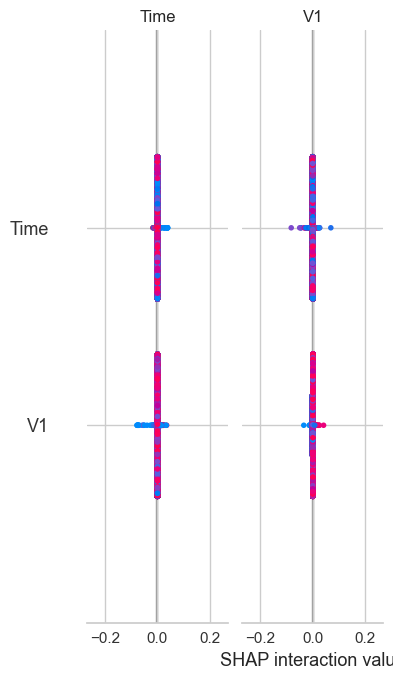

In [4]:
interpret_model(best_model)

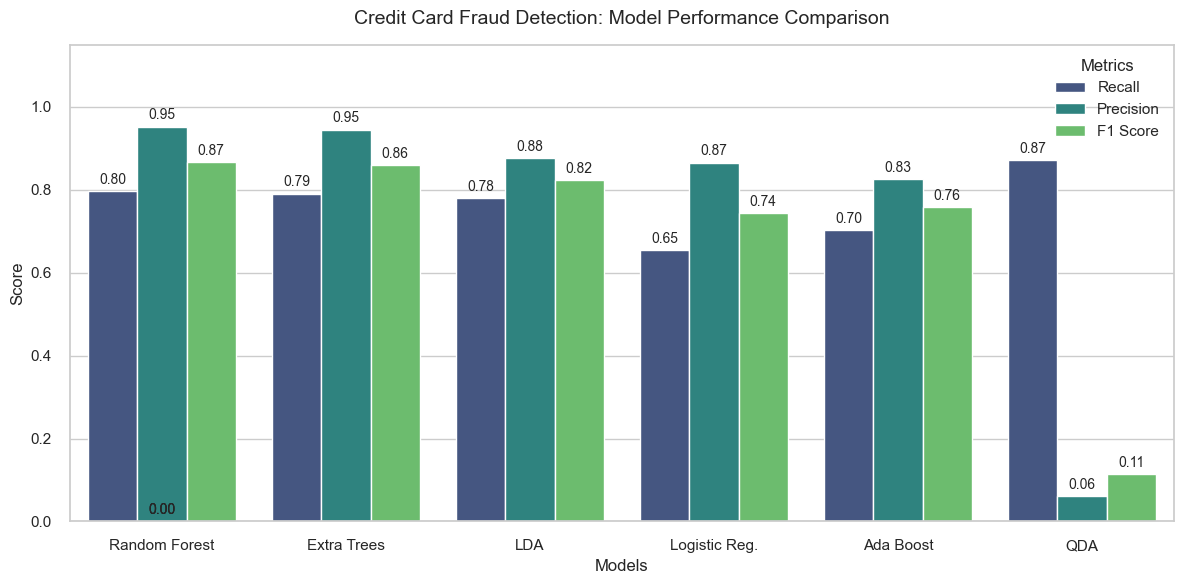

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'Model': ['Random Forest', 'Extra Trees', 'LDA', 'Logistic Reg.', 'Ada Boost', 'QDA'],
    'Recall': [0.7969, 0.7911, 0.7795, 0.6543, 0.7035, 0.8724],
    'Precision': [0.9528, 0.9456, 0.8771, 0.8660, 0.8268, 0.0610],
    'F1 Score': [0.8668, 0.8601, 0.8240, 0.7443, 0.7582, 0.1140]
}
df = pd.DataFrame(data)

df_melted = df.melt(id_vars='Model', var_name='Metrik', value_name='Skor')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.barplot(x='Model', y='Skor', hue='Metrik', data=df_melted, palette='viridis')

plt.title('Credit Card Fraud Detection: Model Performance Comparison', fontsize=14, pad=15)
plt.ylabel('Score', fontsize=12)
plt.xlabel('Models', fontsize=12)
plt.ylim(0, 1.15)
plt.legend(loc='upper right', title='Metrics')

# Skorları barların üzerine ekleme
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 8), 
                textcoords = 'offset points',
                fontsize=10)

plt.tight_layout()
plt.show()

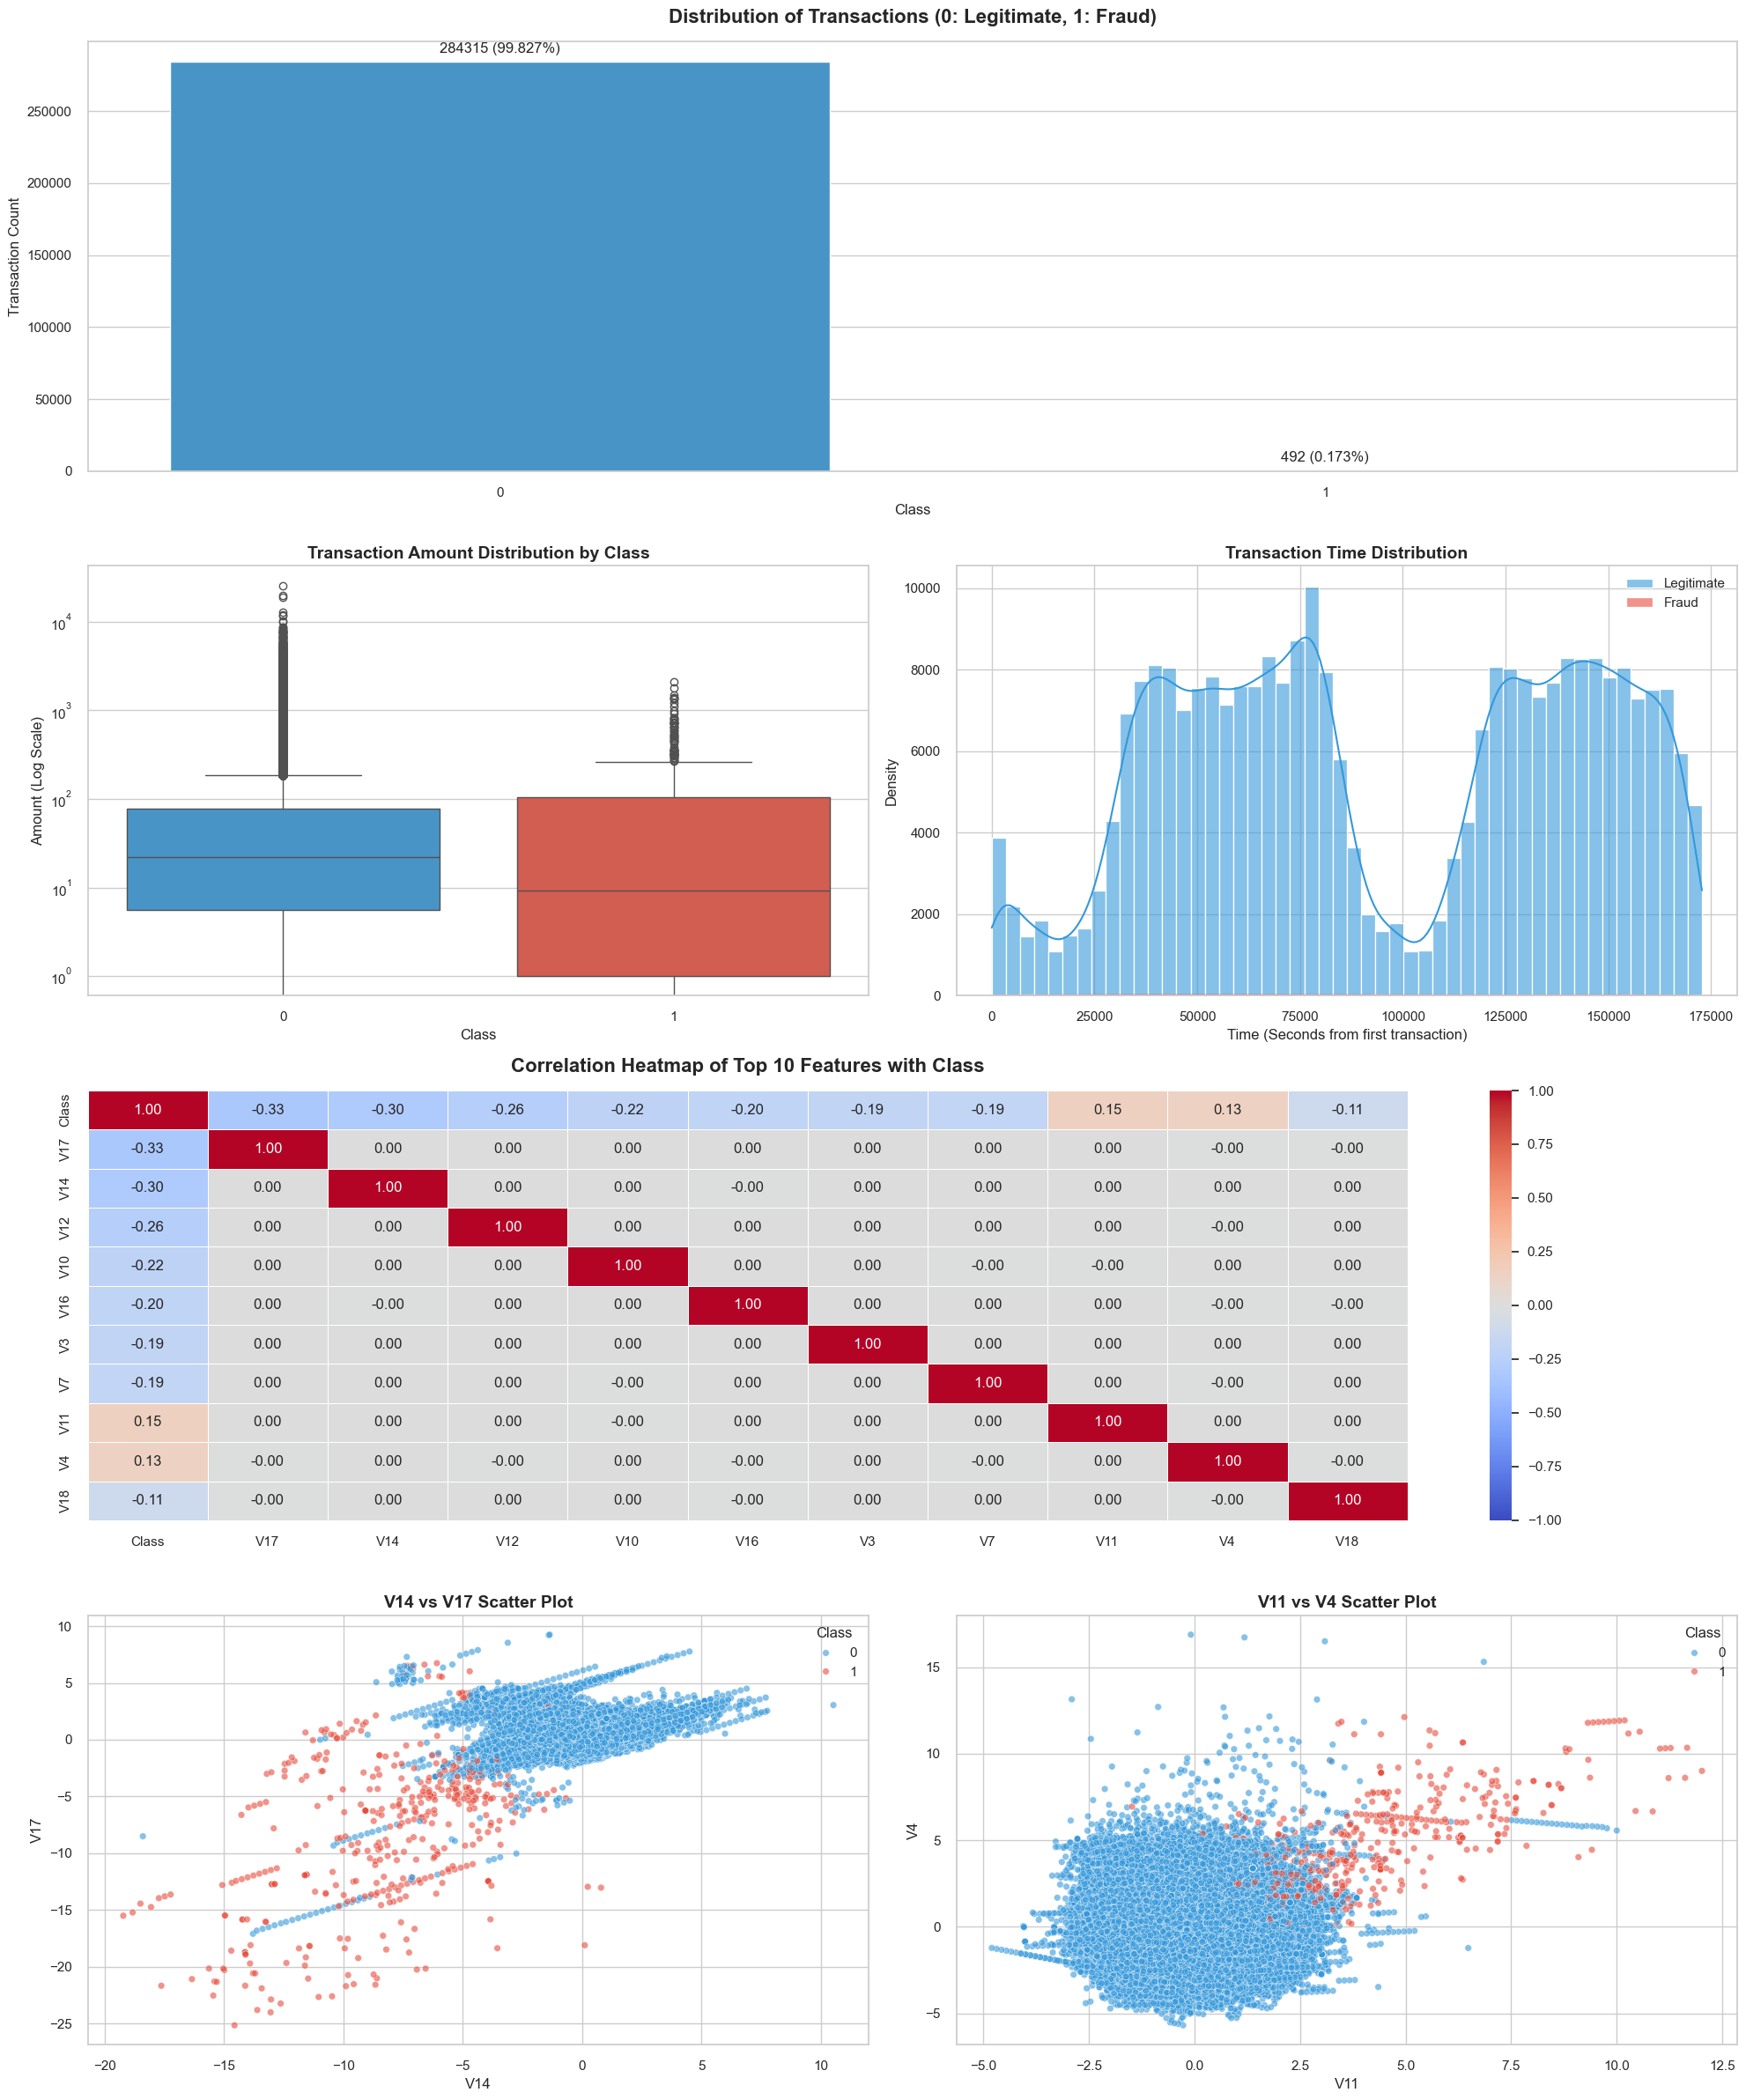

In [10]:

import matplotlib.gridspec as gridspec

# Set general plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12})
df = pd.read_csv('creditcard.csv')
# Assuming your dataframe is loaded as 'df'
# df = pd.read_csv('../input/creditcardfraud/creditcard.csv')

# Create a figure with custom layout using GridSpec
fig = plt.figure(figsize=(20, 24))
gs = gridspec.GridSpec(4, 2, figure=fig)

# -----------------------------------------------------------
# 1. Class Distribution (Target Variable)
# -----------------------------------------------------------
ax1 = fig.add_subplot(gs[0, :])
sns.countplot(x='Class', data=df, ax=ax1, palette=['#3498db', '#e74c3c'])
ax1.set_title('Distribution of Transactions (0: Legitimate, 1: Fraud)', fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel('Class')
ax1.set_ylabel('Transaction Count')

# Add percentage annotations
total = len(df)
for p in ax1.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.3f}%'
    ax1.annotate(f'{int(height)} ({percentage})', 
                 (p.get_x() + p.get_width() / 2., height), 
                 ha='center', va='bottom', fontsize=12, xytext=(0, 5), textcoords='offset points')

# -----------------------------------------------------------
# 2. Transaction Amount Distribution by Class
# -----------------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])
sns.boxplot(x='Class', y='Amount', data=df, ax=ax2, palette=['#3498db', '#e74c3c'])
ax2.set_title('Transaction Amount Distribution by Class', fontsize=14, fontweight='bold')
ax2.set_yscale('log') # Log scale is better for highly skewed amount data
ax2.set_ylabel('Amount (Log Scale)')

# -----------------------------------------------------------
# 3. Transaction Time Distribution by Class
# -----------------------------------------------------------
ax3 = fig.add_subplot(gs[1, 1])
sns.histplot(df[df['Class'] == 0]['Time'], bins=50, color='#3498db', kde=True, label='Legitimate', ax=ax3, alpha=0.6)
sns.histplot(df[df['Class'] == 1]['Time'], bins=50, color='#e74c3c', kde=True, label='Fraud', ax=ax3, alpha=0.6)
ax3.set_title('Transaction Time Distribution', fontsize=14, fontweight='bold')
ax3.set_xlabel('Time (Seconds from first transaction)')
ax3.set_ylabel('Density')
ax3.legend()

# -----------------------------------------------------------
# 4. Correlation Heatmap (Focusing on features strongly correlated with Class)
# -----------------------------------------------------------
ax4 = fig.add_subplot(gs[2, :])
# Getting top 10 features most correlated (positively or negatively) with 'Class'
corr = df.corr()
top_corr_features = corr['Class'].abs().sort_values(ascending=False).head(11).index
sns.heatmap(df[top_corr_features].corr(), cmap='coolwarm', annot=True, fmt=".2f", 
            linewidths=0.5, ax=ax4, vmin=-1, vmax=1)
ax4.set_title('Correlation Heatmap of Top 10 Features with Class', fontsize=16, fontweight='bold', pad=15)

# -----------------------------------------------------------
# 5. Scatter Plot of Top 2 Highly Negative Correlated Features (e.g., V14 & V17)
# -----------------------------------------------------------
ax5 = fig.add_subplot(gs[3, 0])
sns.scatterplot(x='V14', y='V17', hue='Class', data=df, palette=['#3498db', '#e74c3c'], 
                alpha=0.6, ax=ax5, s=30)
ax5.set_title('V14 vs V17 Scatter Plot', fontsize=14, fontweight='bold')
ax5.set_xlabel('V14')
ax5.set_ylabel('V17')

# -----------------------------------------------------------
# 6. Scatter Plot of Top 2 Highly Positive Correlated Features (e.g., V11 & V4)
# -----------------------------------------------------------
ax6 = fig.add_subplot(gs[3, 1])
sns.scatterplot(x='V11', y='V4', hue='Class', data=df, palette=['#3498db', '#e74c3c'], 
                alpha=0.6, ax=ax6, s=30)
ax6.set_title('V11 vs V4 Scatter Plot', fontsize=14, fontweight='bold')
ax6.set_xlabel('V11')
ax6.set_ylabel('V4')

plt.tight_layout()
plt.show()